# Análise exploratória de dados sísmicos e modelos de velocidade

Conjunto principal: Marmousi. Os exemplos finais aplicam os mesmos recursos ao FlatFault_A e ao CurveFault_B.

Fluxo: arquivos e configuração → tensores e eixos → amostra e visualização → estatísticas e integridade → geometria de aquisição → modelagem direta e comparação.

`raw_x` contém os registros sísmicos. `raw_y` contém os modelos de velocidade correspondentes. O escopo é a inspeção e visualização dos dados, sem treinamento de redes neurais.


In [1]:
import inspect
from pathlib import Path

from IPython.display import Image, display

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import deepwave

from config.config import (
    config_for_dataset,
    load_physics_config,
    load_training_config,
    resolve_device,
)
from utils import seed_everything

from data.dataset import prepare_data
from data.files import resolve_dataset_files
from physics.forward import build_forward_operator
from visualization.charts.data_overview import plot_dataset_overview
from visualization.charts.seismic import plot_seismic_comparison
from visualization.wavefield_animation import (
    WavefieldFrameRecorder,
    save_wavefield_gif,
)


## 1. Configuração do conjunto e localização dos arquivos

A configuração base fornece caminhos e parâmetros do experimento. `config_for_dataset` aplica as opções específicas do Marmousi. Os caminhos dos arquivos sísmicos e de velocidade são exibidos antes do carregamento.


In [2]:
CONFIG_PATH = Path("config/models/pgnn_mardan_2024_config.json")
DATASET_NAME = "Marmousi"
config = config_for_dataset(load_training_config(CONFIG_PATH), DATASET_NAME)
DEVICE = resolve_device(config.get("device", "cuda_if_available"))
seed_everything(config.get("seed", 42))

DATASETS_ROOT = Path(config["datasets_root"])
MAX_SAMPLES = config.get("max_samples")

data_file, velocity_file = resolve_dataset_files(DATASETS_ROOT, DATASET_NAME)
print("Conjunto de dados:", DATASET_NAME)
print("Arquivo sísmico:", data_file)
print("Arquivo de velocidade:", velocity_file)
print("Máximo de amostras:", MAX_SAMPLES)


Conjunto de dados: Marmousi
Arquivo sísmico: /home/caiopinho/projects/tcc-fwi/datasets/Marmousi/data/data1.npy
Arquivo de velocidade: /home/caiopinho/projects/tcc-fwi/datasets/Marmousi/model/model1.npy
Máximo de amostras: 2


## 2. Carregamento e estrutura dos tensores

`prepare_data` carrega os pares de registros sísmicos e modelos de velocidade, junto das configurações físicas e da geometria de aquisição.

- `raw_x`: `[amostra, fonte, tempo, receptor]`. Cada fonte corresponde a um tiro sísmico, com uma série temporal registrada em cada receptor.
- `raw_y`: `[amostra, canal, z, x]`. Cada item é um modelo de velocidade em uma grade espacial. O eixo `canal` normalmente tem tamanho 1.

A mesma posição nos eixos de amostra de `raw_x` e `raw_y` identifica um par de registros sísmicos e seu modelo de velocidade associado.


In [3]:
data = prepare_data(config, DEVICE)
raw_x, raw_y = data["raw_x"], data["raw_y"]
PHYSICS_CONFIG = data["physics_config"]
print("Mecanismo de modelagem direta:", PHYSICS_CONFIG.get("forward_backend", "openfwi"))

print("Formato de raw_x [amostra, fonte, tempo, receptor]:", raw_x.shape)
print("Formato de raw_y [amostra, canal, z, x]:", raw_y.shape)
print("Tipo de raw_x:", raw_x.dtype)
print("Tipo de raw_y:", raw_y.dtype)
assert raw_x.ndim == 4
assert raw_y.ndim == 4
assert raw_x.shape[0] == raw_y.shape[0]


Mecanismo de modelagem direta: deepwave
Formato de raw_x [amostra, fonte, tempo, receptor]: (2, 22, 801, 447)
Formato de raw_y [amostra, canal, z, x]: (2, 1, 116, 227)
Tipo de raw_x: float32
Tipo de raw_y: float32


## 3. Inspeção de uma amostra

A amostra selecionada é a de índice 0. `seismic` reúne seus tiros e `velocity` contém o mapa de velocidade correspondente. Os formatos impressos identificam os eixos antes da visualização.

A variável `sample_id` seleciona outra amostra, desde que o índice exista nos dois tensores.


In [4]:
sample_id = 0
seismic = raw_x[sample_id]
velocity = raw_y[sample_id, 0]

print("ID da amostra:", sample_id)
print("Formato da amostra sísmica [fonte, tempo, receptor]:", seismic.shape)
print("Formato da amostra de velocidade [z, x]:", velocity.shape)
print("Quantidade de fontes:", seismic.shape[0])
print("Passos de tempo:", seismic.shape[1])
print("Receptores:", seismic.shape[2])


ID da amostra: 0
Formato da amostra sísmica [fonte, tempo, receptor]: (22, 801, 447)
Formato da amostra de velocidade [z, x]: (116, 227)
Quantidade de fontes: 22
Passos de tempo: 801
Receptores: 447


## 4. Visualização inicial

A figura contém três painéis: registro do primeiro tiro, média dos registros entre os tiros e modelo de velocidade. Os registros sísmicos incluem receptores de superfície e receptores posicionados nos dois poços laterais, conforme a geometria de aquisição do Marmousi. Nos painéis sísmicos, os eixos representam índices de receptor e de tempo. No modelo, representam posição `x` e profundidade `z` em células.

A média resume padrões comuns entre os tiros. A inspeção de um tiro individual continua disponível nos registros originais.


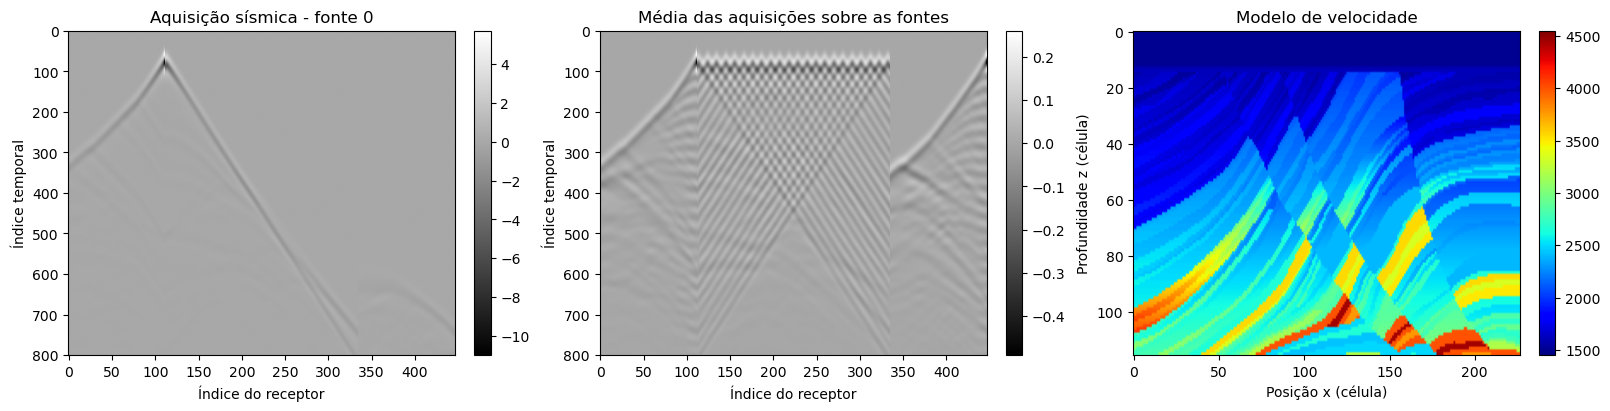

In [5]:
fig, axes = plot_dataset_overview(
    seismic,
    velocity,
    physics_config=PHYSICS_CONFIG,
)


## 5. Escalas e integridade dos dados

As verificações abrangem todos os dados carregados, não apenas a amostra 0. A tabela resume valores e entradas não finitas. O histograma mostra a distribuição das velocidades, sem preservar sua posição espacial. A triagem final sinaliza amostras com valores não finitos ou desvio padrão zero. Esse critério não substitui uma análise completa de ruído.


### Resumo numérico

Mínimo, máximo, média, desvio padrão e contagens de valores não finitos para sísmica e velocidade.


In [6]:
def describe(name, values):
    values = np.asarray(values)
    return {
        "name": name,
        "min": float(np.nanmin(values)),
        "max": float(np.nanmax(values)),
        "mean": float(np.nanmean(values)),
        "std": float(np.nanstd(values)),
        "nan_count": int(np.isnan(values).sum()),
        "inf_count": int(np.isinf(values).sum()),
    }

stats = pd.DataFrame([
    describe("seismic", raw_x),
    describe("velocity", raw_y),
])
stats


,name,min,max,mean,std,nan_count,inf_count
0,seismic,-10.997049,5.73187,-0.000095,0.191495,0,0
1,velocity,1500.000000,4450.00000,2281.859131,624.892151,0,0


### Distribuição da velocidade

Histograma dos valores de velocidade em todas as amostras carregadas.


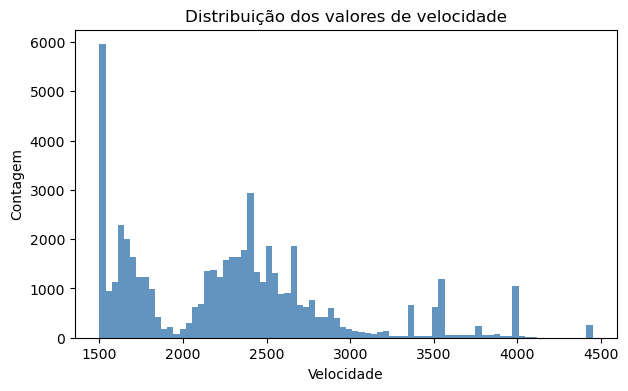

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(raw_y.reshape(-1), bins=80, color="steelblue", alpha=0.85)
ax.set_title("Distribuição dos valores de velocidade")
ax.set_xlabel("Velocidade")
ax.set_ylabel("Contagem")
plt.show()


### Triagem de amostras

Sinalização de amostras com valores `NaN`, infinitos ou desvio padrão zero.


In [8]:
corrupted = []
for idx in range(raw_x.shape[0]):
    if not np.isfinite(raw_x[idx]).all() or not np.isfinite(raw_y[idx]).all():
        corrupted.append(idx)
    elif np.nanstd(raw_x[idx]) == 0 or np.nanstd(raw_y[idx]) == 0:
        corrupted.append(idx)

print("Amostras possivelmente ruidosas/corrompidas:", corrupted[:20])
print("Quantidade:", len(corrupted))

Amostras possivelmente ruidosas/corrompidas: []
Quantidade: 0


## 6. Geometria de aquisição antes de mostrar os tiros

A figura sobrepõe fontes e receptores ao modelo de velocidade. As coordenadas são armazenadas em células na ordem `[x, z]`; o espaçamento da malha converte essas posições para metros.

Estrelas vermelhas: fontes. Pontos azuis: receptores de superfície. Pontos laranja: receptores nos dois poços laterais.


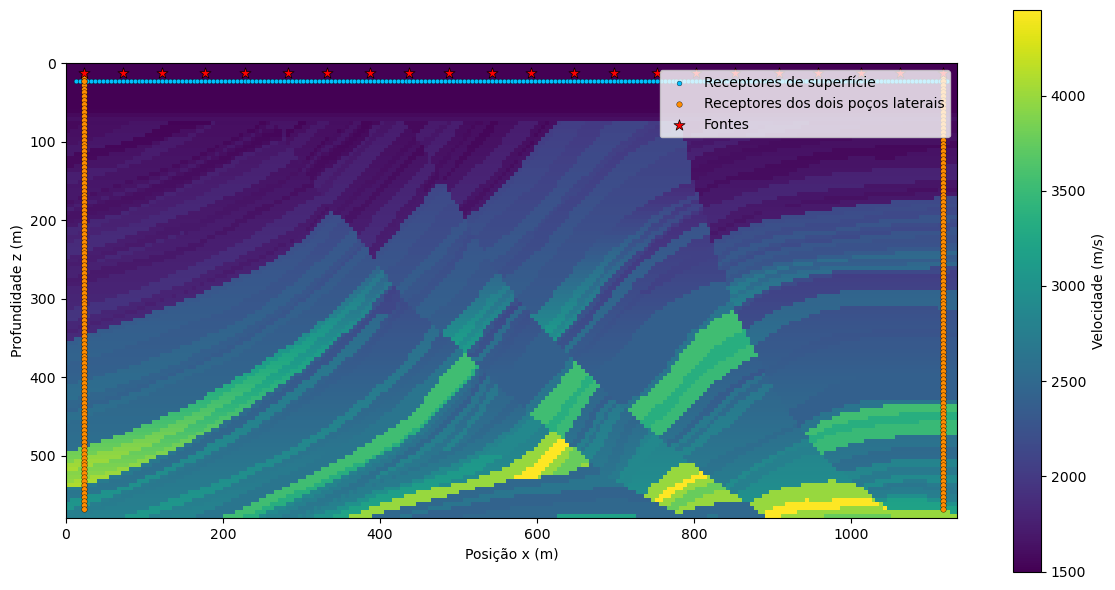

In [9]:
source_indices = data["source_indices"]
receiver_indices = data["receiver_indices"]
if source_indices is None or receiver_indices is None:
    raise ValueError("A geometria explícita de fontes e receptores é necessária para esta figura.")

model_depth, model_width = velocity.shape
grid_spacing_m = float(PHYSICS_CONFIG["grid_spacing_m"])
receiver_x = receiver_indices[:, 0]
receiver_z = receiver_indices[:, 1]
surface_mask = receiver_z == int(PHYSICS_CONFIG["surface_receiver_depth_index"])
well_x_margin = int(PHYSICS_CONFIG["well_receiver_x_margin_cells"])
well_x_positions = [well_x_margin, model_width - well_x_margin]
well_mask = np.isin(receiver_x, well_x_positions)

fig, ax = plt.subplots(figsize=(12, 6))
image = ax.imshow(
    velocity,
    cmap="viridis",
    origin="upper",
    aspect="equal",
    extent=(0, model_width * grid_spacing_m, model_depth * grid_spacing_m, 0),
)
ax.scatter(
    (receiver_x[surface_mask] + 0.5) * grid_spacing_m,
    (receiver_z[surface_mask] + 0.5) * grid_spacing_m,
    s=12,
    color="deepskyblue",
    edgecolors="black",
    linewidths=0.25,
    label="Receptores de superfície",
    zorder=3,
)
ax.scatter(
    (receiver_x[well_mask] + 0.5) * grid_spacing_m,
    (receiver_z[well_mask] + 0.5) * grid_spacing_m,
    s=16,
    color="darkorange",
    edgecolors="black",
    linewidths=0.25,
    label="Receptores dos dois poços laterais",
    zorder=4,
)
ax.scatter(
    (source_indices[:, 0] + 0.5) * grid_spacing_m,
    (source_indices[:, 1] + 0.5) * grid_spacing_m,
    s=70,
    marker="*",
    color="red",
    edgecolors="black",
    linewidths=0.5,
    label="Fontes",
    zorder=5,
)
fig.colorbar(image, ax=ax, label="Velocidade (m/s)")
ax.set_xlabel("Posição x (m)")
ax.set_ylabel("Profundidade z (m)")
ax.legend(loc="upper right")
fig.tight_layout()


## 7. Modelagem direta da amostra

O operador usa o modelo de velocidade selecionado e a geometria da aquisição para calcular registros sísmicos previstos. A comparação com `raw_x` ocorre na etapa seguinte.


In [10]:
if source_indices is None or receiver_indices is None:
    raise ValueError("A geometria explícita de fontes e receptores é obrigatória para esta análise.")

observed_seismic = torch.as_tensor(
    raw_x[sample_id : sample_id + 1],
    dtype=torch.float32,
    device=DEVICE,
)
true_velocity = torch.as_tensor(
    raw_y[sample_id : sample_id + 1],
    dtype=torch.float32,
    device=DEVICE,
)

forward_operator = build_forward_operator(
    source_indices=source_indices,
    receiver_count=raw_x[sample_id].shape[-1],
    time_step_count=raw_x[sample_id].shape[1],
    receiver_indices=receiver_indices,
    receiver_z_index=1,
    config=PHYSICS_CONFIG,
).to(DEVICE)


GIF do campo de ondas: results/data_analysis/figures/seismic_acquisition/Marmousi_s0000_forward_wavefield.gif


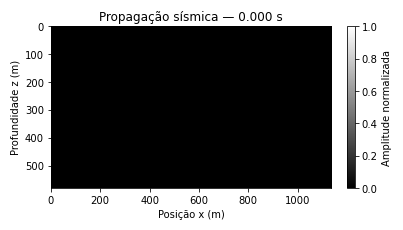

Dispositivo: cuda (CUDA disponível: True)
Formato dos dados sísmicos previstos: (1, 22, 801, 447)
Formato dos dados sísmicos observados: (1, 22, 801, 447)


In [11]:
# Modelagem direta com velocidade de referência e geometria da aquisição.
callback_parameters = set()
try:
    callback_parameters = set(inspect.signature(deepwave.scalar).parameters)
except (TypeError, ValueError):
    pass

native_callback_available = {
    "forward_callback",
    "callback_frequency",
}.issubset(callback_parameters)

wavefield_recorder = None
with torch.no_grad():
    if native_callback_available:
        wavefield_recorder = WavefieldFrameRecorder()
        predicted_seismic = forward_operator(
            true_velocity,
            wavefield_callback=wavefield_recorder,
            callback_frequency=10,
        )
    else:
        predicted_seismic = forward_operator(true_velocity)
        print(
            "Animação do campo de ondas ignorada: esta versão do Deepwave "
            "não oferece callbacks nativos. Os registros sísmicos foram calculados."
        )

if native_callback_available:
    DATA_ANALYSIS_WAVEFIELD_GIF = (
        Path("results/data_analysis/figures/seismic_acquisition")
        / f"{DATASET_NAME}_s{sample_id:04d}_forward_wavefield.gif"
    )
    save_wavefield_gif(
        wavefield_recorder,
        DATA_ANALYSIS_WAVEFIELD_GIF,
        grid_spacing_m=float(PHYSICS_CONFIG["grid_spacing_m"]),
    )
    print("GIF do campo de ondas:", DATA_ANALYSIS_WAVEFIELD_GIF)
    display(Image(filename=str(DATA_ANALYSIS_WAVEFIELD_GIF)))

print(f"Dispositivo: {DEVICE} (CUDA disponível: {torch.cuda.is_available()})")
print(f"Formato dos dados sísmicos previstos: {tuple(predicted_seismic.shape)}")
print(f"Formato dos dados sísmicos observados: {tuple(observed_seismic.shape)}")

assert predicted_seismic.shape == observed_seismic.shape, (
    f"Incompatibilidade de formatos: previsto={tuple(predicted_seismic.shape)}, "
    f"alvo={tuple(observed_seismic.shape)}"
)


### Comparação dos registros sísmicos

O painel exibe o registro previsto, o registro correspondente em `raw_x` e a diferença entre eles. `SOURCE_TO_COMPARE` define o tiro exibido.

A comparação verifica a compatibilidade entre configuração, geometria e modelagem direta. Não há ajuste de parâmetros ou treinamento nesta etapa.


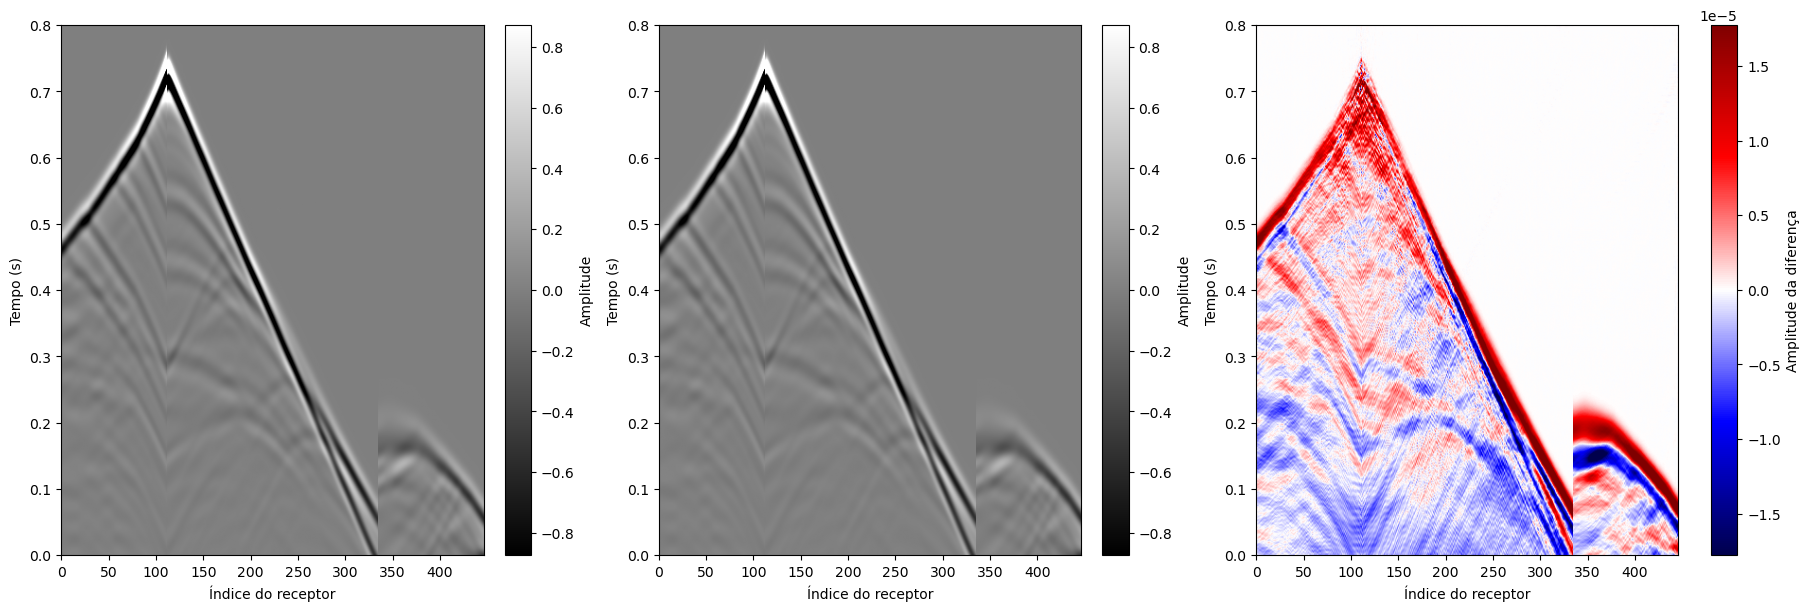

In [12]:
# Índice da fonte usado na comparação.
SOURCE_TO_COMPARE = 0
if not 0 <= SOURCE_TO_COMPARE < predicted_seismic.shape[1]:
    raise ValueError(f"SOURCE_TO_COMPARE deve estar entre 0 e {predicted_seismic.shape[1] - 1}")

comparison_figure, comparison_axes = plot_seismic_comparison(
    predicted_seismic_data=(
        predicted_seismic[0, SOURCE_TO_COMPARE].detach().cpu().numpy()
    ),
    target_seismic_data=(
        observed_seismic[0, SOURCE_TO_COMPARE].detach().cpu().numpy()
    ),
    time_spacing_s=PHYSICS_CONFIG["time_spacing_s"],
    receiver_spacing_m=(
        1.0 if receiver_indices is not None
        else PHYSICS_CONFIG["receiver_line_spacing_m"]
    ),
    receiver_axis_label=(
        "Índice do receptor"
        if receiver_indices is not None else "Posição do receptor (m)"
    ),
    show=True,
)


## 8. Exemplo: FlatFault_A

Aplicação da mesma visualização ao conjunto FlatFault_A. A figura reúne uma aquisição sísmica e seu modelo de velocidade. O arquivo exportado é usado na Figura 1 da dissertação.

A configuração do conjunto define caminhos e escala física próprios. A figura utiliza a amostra 0.


Figura 1 exportada: results/data_analysis/figures/thesis/FlatFault_A_s0000_entrada_saida.png


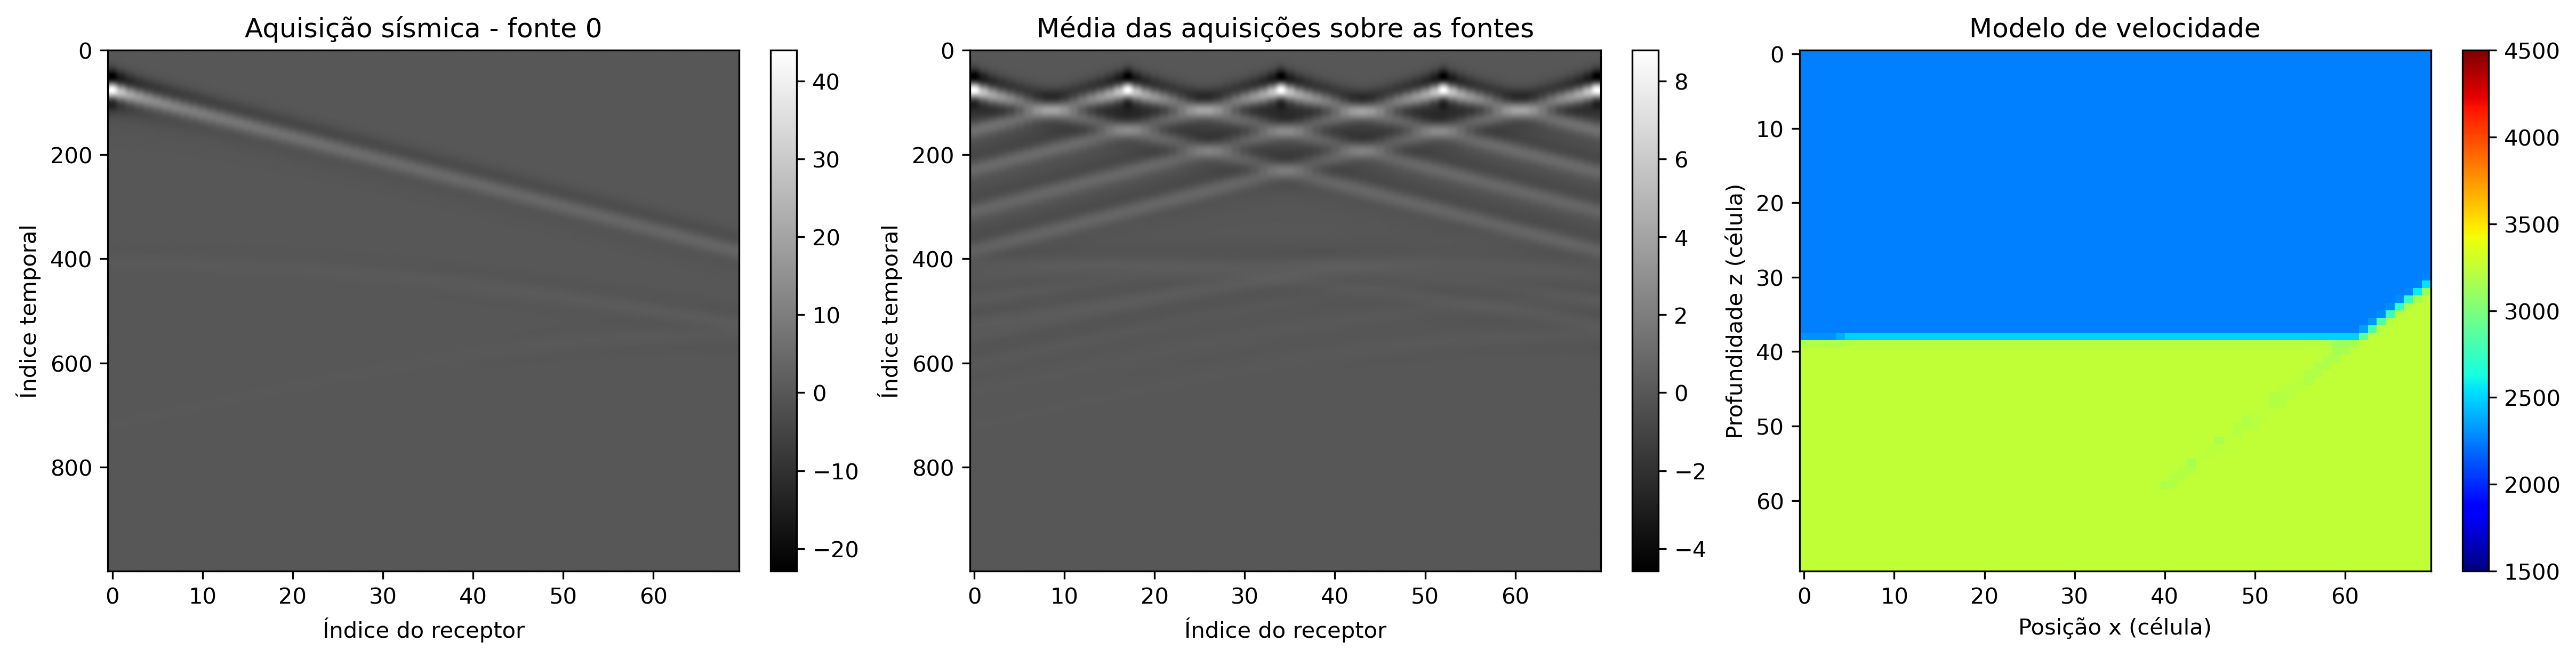

In [13]:
FIGURE_1_DATASET = "FlatFault_A"
figure_1_config = config_for_dataset(
    load_training_config(CONFIG_PATH), FIGURE_1_DATASET
)
figure_1_data = prepare_data(figure_1_config, DEVICE)
FIGURE_1_SAMPLE_ID = 0
FIGURE_1_OUTPUT = (
    Path("results/data_analysis/figures/thesis")
    / f"{FIGURE_1_DATASET}_s{FIGURE_1_SAMPLE_ID:04d}_entrada_saida.png"
)
FIGURE_1_OUTPUT.parent.mkdir(parents=True, exist_ok=True)
plot_dataset_overview(
    figure_1_data["raw_x"][FIGURE_1_SAMPLE_ID],
    figure_1_data["raw_y"][FIGURE_1_SAMPLE_ID, 0],
    physics_config=figure_1_data["physics_config"],
    save_path=FIGURE_1_OUTPUT,
    show=False,
)
print("Figura 1 exportada:", FIGURE_1_OUTPUT)
display(Image(filename=str(FIGURE_1_OUTPUT)))


## 9. Exemplo: CurveFault_B

Este bloco carrega apenas um modelo de velocidade do CurveFault_B. O acesso mapeado em memória permite ler uma amostra sem carregar o shard inteiro.

A escala de cores e os eixos em metros vêm da configuração física do conjunto. Quando os arquivos não estão disponíveis no caminho configurado, a célula informa a ausência e não gera a figura.


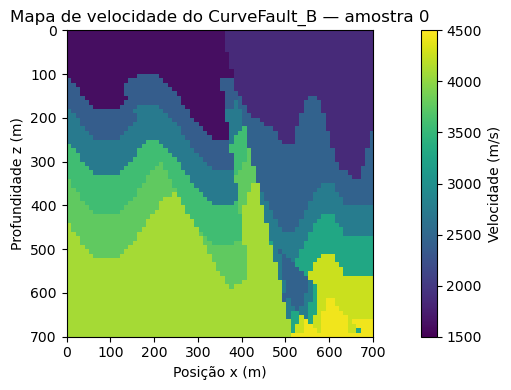

In [14]:
CURVEFAULT_B_CONFIG = config_for_dataset(
    load_training_config(CONFIG_PATH),
    "CurveFault_B",
)
CURVEFAULT_B_DATASETS_ROOT = Path(CURVEFAULT_B_CONFIG["datasets_root"])
CURVEFAULT_B_SAMPLE_ID = 0

try:
    _, CURVEFAULT_B_velocity_file = resolve_dataset_files(CURVEFAULT_B_DATASETS_ROOT, "CurveFault_B")
except FileNotFoundError as exc:
    print(f"Conjunto de dados CurveFault_B indisponível: {exc}")
else:
    CURVEFAULT_B_velocity_shard = np.load(CURVEFAULT_B_velocity_file, mmap_mode="r")
    CURVEFAULT_B_velocity = np.asarray(CURVEFAULT_B_velocity_shard[CURVEFAULT_B_SAMPLE_ID])
    if CURVEFAULT_B_velocity.ndim == 3 and CURVEFAULT_B_velocity.shape[0] == 1:
        CURVEFAULT_B_velocity = CURVEFAULT_B_velocity[0]
    if CURVEFAULT_B_velocity.ndim != 2:
        raise ValueError(f"Esperava um mapa de velocidade [profundidade, largura]; recebido {CURVEFAULT_B_velocity.shape}")

    CURVEFAULT_B_physics = load_physics_config(CURVEFAULT_B_CONFIG["physics_config"])
    grid_spacing_m = float(CURVEFAULT_B_physics["grid_spacing_m"])
    depth, width = CURVEFAULT_B_velocity.shape
    fig, ax = plt.subplots(figsize=(10, 4))
    image = ax.imshow(
        CURVEFAULT_B_velocity,
        cmap="viridis",
        origin="upper",
        aspect="equal",
        extent=(0, width * grid_spacing_m, depth * grid_spacing_m, 0),
        vmin=CURVEFAULT_B_physics["velocity_min"],
        vmax=CURVEFAULT_B_physics["velocity_max"],
    )
    fig.colorbar(image, ax=ax, label="Velocidade (m/s)")
    ax.set_xlabel("Posição x (m)")
    ax.set_ylabel("Profundidade z (m)")
    ax.set_title(f"Mapa de velocidade do CurveFault_B — amostra {CURVEFAULT_B_SAMPLE_ID}")
    fig.tight_layout()
    plt.show()

## Síntese

O fluxo abrange localização de arquivos, leitura dos tensores, inspeção visual, verificação numérica, geometria de aquisição e comparação entre dados observados e modelados. FlatFault_A e CurveFault_B ilustram a aplicação das mesmas operações a estruturas de dados diferentes.